# Data Cleaning, Labelling Review & EDA — Dataset Deteksi Cacat Fisik (Roboflow v5)

Notebook ini menggantikan versi v4 sebelumnya agar seluruh statistik **Data Cleaning**, **Exploratory Data Analysis (EDA)**, **Data Splitting**, dan **Visualisasi Pra-Pemrosesan** pada **Bab III Laporan** selaras 100% dengan dataset **Roboflow Card-Grader Versi 5** yang digunakan melatih model final `YOLO26s` (`modeling_card_condition.ipynb`).

* **Sumber Dataset:** Roboflow Universe (`group-6-major-project` / `card-grader`, **Version 5**)
* **Lisensi:** CC BY 4.0
* **Kelas Target (4 Kelas):** `Card`, `Corner Wear`, `Edge Wear`, `Scratch`

In [9]:
import os
import sys
import glob
import hashlib
import random
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

CLASSES = ["Card", "Corner Wear", "Edge Wear", "Scratch"]
CLASS_COLORS_RGB = {
    0: (41, 128, 185),   # Card (Biru)
    1: (211, 84, 0),     # Corner Wear (Oranye)
    2: (39, 174, 96),    # Edge Wear (Hijau)
    3: (192, 57, 43),    # Scratch (Merah)
}
PALETTE_HEX = ["#2980B9", "#D35400", "#27AE60", "#C0392B"]

# Deteksi lingkungan (Kaggle vs Lokal)
IS_KAGGLE = os.path.exists("/kaggle/working")
if IS_KAGGLE:
    OUTPUT_DIR = Path("/kaggle/working/eda_v5_outputs")
    DATASET_BASE = Path("/kaggle/working/card-grader-v5")
else:
    cwd = Path.cwd().resolve()
    backend_dir = cwd.parent if cwd.name == "notebooks" else (cwd / "backend" if (cwd / "backend").exists() else cwd)
    OUTPUT_DIR = backend_dir / "dataset" / "eda_v5_outputs"
    DATASET_BASE = backend_dir / "dataset" / "card-condition-dataset-v5"

def fmt_path(p: Path) -> str:
    """Menampilkan path relatif dari root proyek agar path lokal absolut tidak terekspos."""
    if IS_KAGGLE:
        return str(p)
    try:
        return p.relative_to(backend_dir.parent).as_posix()
    except ValueError:
        return p.name

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Lingkungan : {'Kaggle' if IS_KAGGLE else 'Lokal'}")
print(f"Dataset dir: {fmt_path(DATASET_BASE)}")
print(f"Output dir : {fmt_path(OUTPUT_DIR)}")

Lingkungan : Lokal
Dataset dir: backend/dataset/card-condition-dataset-v5
Output dir : backend/dataset/eda_v5_outputs


In [10]:
# Unduh Dataset Roboflow Versi 5 (otomatis melewati unduhan jika folder sudah ada)
from roboflow import Roboflow

if not (DATASET_BASE / "train" / "images").exists():
    api_key = None
    if IS_KAGGLE:
        from kaggle_secrets import UserSecretsClient
        api_key = UserSecretsClient().get_secret("api_key")
    else:
        from dotenv import load_dotenv
        load_dotenv(backend_dir / ".env")
        api_key = os.getenv("ROBOFLOW_API_KEY") or os.getenv("api_key")

    if not api_key:
        raise ValueError("ROBOFLOW_API_KEY tidak ditemukan di backend/.env maupun Kaggle Secrets.")

    rf = Roboflow(api_key=api_key)
    project = rf.workspace("group-6-major-project").project("card-grader")
    version = project.version(5)
    dl_location = str(DATASET_BASE) if IS_KAGGLE else os.path.relpath(DATASET_BASE, Path.cwd())
    try:
        dataset = version.download("yolo26", location=dl_location)
    except Exception:
        dataset = version.download("yolov8", location=dl_location)
    print(f"Dataset v5 berhasil diunduh ke: {fmt_path(DATASET_BASE)}")
else:
    print(f"Dataset v5 sudah tersedia di: {fmt_path(DATASET_BASE)}")

# Normalisasi nama folder validasi (Roboflow biasanya menamai 'valid')
SPLITS = ["train", "valid" if (DATASET_BASE / "valid").exists() else "val", "test"]
print("Split terdeteksi:", SPLITS)

Dataset v5 sudah tersedia di: backend/dataset/card-condition-dataset-v5
Split terdeteksi: ['train', 'valid', 'test']


## 1. Audit Integritas Data (Data Cleaning)
Memeriksa empat aspek kualitas data sesuai pedoman laporan:
1. **File citra korup** (`Image.verify()`).
2. **Duplikasi citra** lintas maupun dalam *split* (SHA-256 hash piksel).
3. **Resolusi minimum** citra mentah.
4. **Validitas berkas anotasi `.txt`** (memisahkan berkas yang mencampurkan format poligon segmentasi `> 5` kolom dengan format *bounding box* standar `5` kolom) serta konfirmasi tidak adanya *relabeling* manual.

In [11]:
image_records = []
corrupt_images = []
small_images = []
seen_hashes = {}
duplicate_images = []
corrupt_label_files = []
split_summary_rows = []

for split in SPLITS:
    img_dir = DATASET_BASE / split / "images"
    lbl_dir = DATASET_BASE / split / "labels"
    img_files = sorted(glob.glob(str(img_dir / "*.*")))
    img_files = [p for p in img_files if Path(p).suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}]

    split_corrupt_lbl = 0
    for img_path in img_files:
        p = Path(img_path)
        lbl_path = lbl_dir / f"{p.stem}.txt"

        # 1. Cek integritas gambar
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                w, h = im.size
                img_hash = hashlib.sha256(im.tobytes()).hexdigest()
        except Exception:
            corrupt_images.append((split, p.name))
            continue

        if w < 100 or h < 100:
            small_images.append((split, p.name, w, h))

        if img_hash in seen_hashes:
            duplicate_images.append((split, p.name, seen_hashes[img_hash]))
        else:
            seen_hashes[img_hash] = f"{split}/{p.name}"

        # 2. Cek validitas berkas label YOLO (harus tepat 5 token per baris: class xc yc w h)
        is_label_corrupt = False
        valid_boxes = 0
        if lbl_path.exists():
            with open(lbl_path, "r", encoding="utf-8") as f:
                for line in f:
                    parts = line.strip().split()
                    if not parts:
                        continue
                    if len(parts) != 5:
                        is_label_corrupt = True
                        break
                    try:
                        cls_id = int(parts[0])
                        vals = [float(x) for x in parts[1:]]
                        if cls_id not in range(len(CLASSES)) or any(v < 0 or v > 1 for v in vals):
                            is_label_corrupt = True
                            break
                        valid_boxes += 1
                    except ValueError:
                        is_label_corrupt = True
                        break

        if is_label_corrupt:
            split_corrupt_lbl += 1
            corrupt_label_files.append((split, lbl_path.name))

        image_records.append({
            "split": split,
            "filename": p.name,
            "img_path": str(p),
            "lbl_path": str(lbl_path),
            "width": w,
            "height": h,
            "resolution": f"{w}x{h}",
            "label_corrupt": is_label_corrupt,
            "valid_boxes": valid_boxes,
        })

    total_raw = len(img_files)
    total_clean = total_raw - split_corrupt_lbl
    split_summary_rows.append({
        "Split": split,
        "Citra Mentah": total_raw,
        "Label Korup (Non-BBox)": split_corrupt_lbl,
        "Citra Bersih Valid": total_clean,
    })

df_imgs = pd.DataFrame(image_records)
df_split_summary = pd.DataFrame(split_summary_rows)
df_split_summary["Proporsi (%)"] = (df_split_summary["Citra Bersih Valid"] / df_split_summary["Citra Bersih Valid"].sum() * 100).round(2)

print("=== RINGKASAN DATA CLEANING DATASET ROBOFLOW V5 ===")
print(f"Citra gambar korup     : {len(corrupt_images)}")
print(f"Citra duplikat (SHA256): {len(duplicate_images)}")
print(f"Resolusi < 100x100 px  : {len(small_images)}")
print(f"Berkas label korup     : {len(corrupt_label_files)} (format poligon/non-5 kolom)")
print("Relabeling manual      : Tidak dilakukan (memakai 4 kelas standar bawaan)")
print("\nDistribusi Resolusi Citra Mentah:")
print(df_imgs["resolution"].value_counts().to_string())
print("\nRingkasan per Split:")
display(df_split_summary)
if corrupt_label_files:
    print("\nDaftar berkas label korup yang disingkirkan:")
    for sp, fn in corrupt_label_files:
        print(f"  - [{sp}] {fn}")

=== RINGKASAN DATA CLEANING DATASET ROBOFLOW V5 ===
Citra gambar korup     : 0
Citra duplikat (SHA256): 0
Resolusi < 100x100 px  : 0
Berkas label korup     : 9 (format poligon/non-5 kolom)
Relabeling manual      : Tidak dilakukan (memakai 4 kelas standar bawaan)

Distribusi Resolusi Citra Mentah:
resolution
294x416    944
296x416    560

Ringkasan per Split:


,Split,Citra Mentah,Label Korup (Non-BBox),Citra Bersih Valid,Proporsi (%)
0,train,1311,9,1302,87.09
1,valid,122,0,122,8.16
2,test,71,0,71,4.75



Daftar berkas label korup yang disingkirkan:
  - [train] s-l1600---2022-04-26T112714-306_png.rf.2e843fee81a8481e1a29bc48fc948553.txt
  - [train] s-l1600---2022-04-26T112714-306_png.rf.3941b065bd700495223d25698b3331ee.txt
  - [train] s-l1600---2022-04-26T112714-306_png.rf.e3a7615a22d73d1ace44b4fd4a94bb06.txt
  - [train] s-l1600--14-_jpg.rf.90c4cf6b3cd56b6e00c2ed687fa81d06.txt
  - [train] s-l1600--14-_jpg.rf.bc63051422441789d383a294c77f144e.txt
  - [train] s-l1600--14-_jpg.rf.c5da089f35e57799c991a8550e66e803.txt
  - [train] s-l1600--20-_jpg.rf.7c9e220c58cac7c22b854d625ea23665.txt
  - [train] s-l1600--20-_jpg.rf.8ca3a19c62bc7fd7e7ce2a98bf8505d7.txt
  - [train] s-l1600--20-_jpg.rf.a166f909cfaf181ab8b526b4f7ca56fd.txt


## 2. EDA: Distribusi Kelas, Ketidakseimbangan Skala Objek, & Rasio Split
Menghitung sebaran kotak anotasi pada seluruh data bersih (`label_corrupt == False`) serta mengukur luas relatif objek terhadap gambar (`% area`) dan rasio aspeknya (`w / h`).

split,test,train,valid,Total,Jml Citra Unik
class_name,,,,,
Card,71,1302,121,1494,1475
Corner Wear,120,2550,248,2918,983
Edge Wear,148,3380,327,3855,836
Scratch,104,2735,252,3091,716


,Median_Area_Pct,Mean_Area_Pct,Median_W_800px,Median_H_800px
class_name,,,,
Card,94.16,93.07,772.97,778.85
Corner Wear,0.24,0.26,48.32,32.69
Edge Wear,0.09,0.23,13.51,25.00
Scratch,0.03,0.18,18.79,11.54


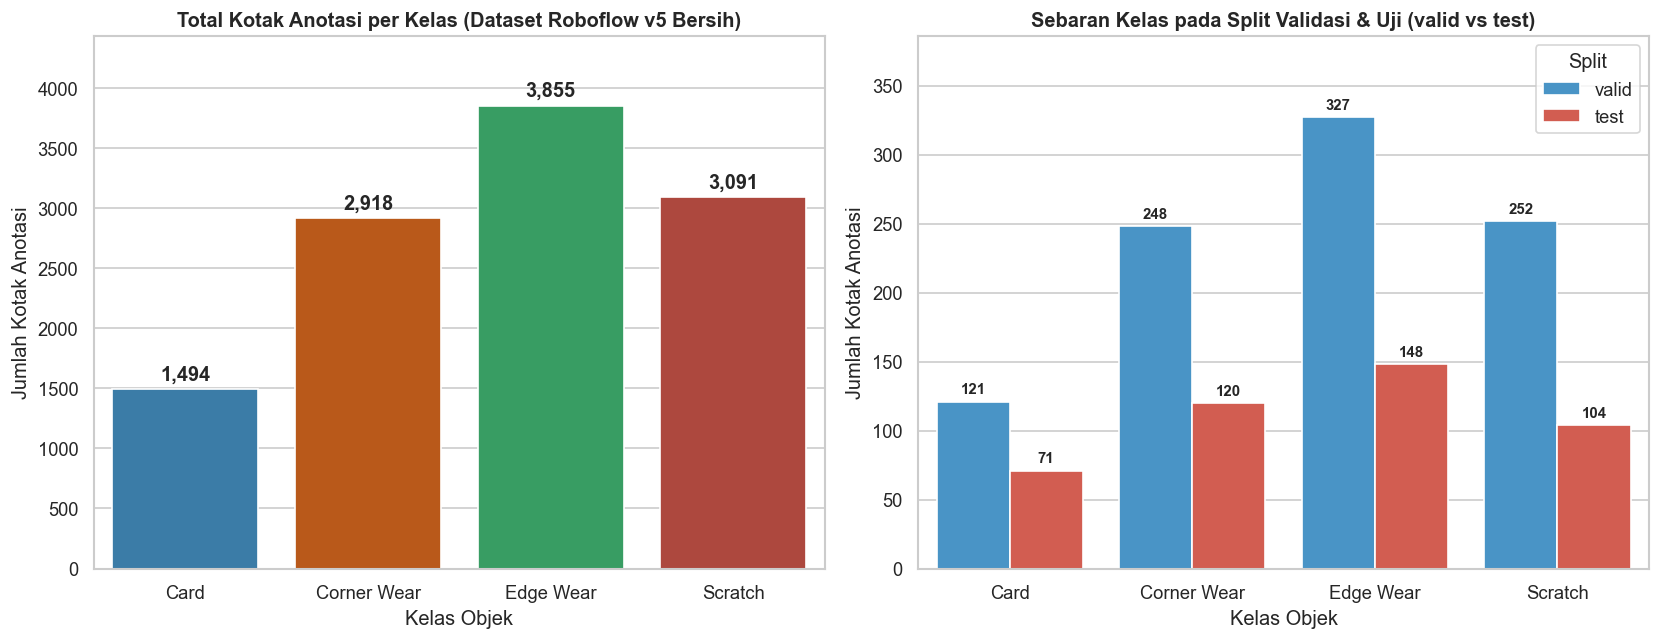

In [12]:
bbox_rows = []
df_clean_imgs = df_imgs[~df_imgs["label_corrupt"]].copy()

for _, row in df_clean_imgs.iterrows():
    lbl_p = Path(row["lbl_path"])
    if not lbl_p.exists():
        continue
    with open(lbl_p, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            cls_id = int(parts[0])
            xc, yc, bw, bh = map(float, parts[1:])
            bbox_rows.append({
                "split": row["split"],
                "filename": row["filename"],
                "class_id": cls_id,
                "class_name": CLASSES[cls_id],
                "xc": xc,
                "yc": yc,
                "w_norm": bw,
                "h_norm": bh,
                "area_pct": bw * bh * 100.0,
                "aspect_ratio": bw / max(bh, 1e-6),
                "w_800px": bw * 800.0,
                "h_800px": bh * 800.0,
            })

df_boxes = pd.DataFrame(bbox_rows)

# Tabel ringkasan per kelas & per split
pivot_counts = pd.pivot_table(
    df_boxes, index="class_name", columns="split", values="filename", aggfunc="count", fill_value=0
).reindex(CLASSES)
pivot_counts["Total"] = pivot_counts.sum(axis=1)

# Hitung jumlah citra unik per kelas
img_presence = df_boxes.groupby("class_name")["filename"].nunique().reindex(CLASSES)
pivot_counts["Jml Citra Unik"] = img_presence

# Statistik ukuran kotak
scale_stats = df_boxes.groupby("class_name").agg(
    Median_Area_Pct=("area_pct", "median"),
    Mean_Area_Pct=("area_pct", "mean"),
    Median_W_800px=("w_800px", "median"),
    Median_H_800px=("h_800px", "median"),
).reindex(CLASSES).round(2)

display(pivot_counts)
display(scale_stats)

# PLOT 1: Distribusi Jumlah Anotasi per Kelas dan Split
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

total_per_cls = pivot_counts["Total"]
ax1 = sns.barplot(x=total_per_cls.index, y=total_per_cls.values, hue=total_per_cls.index, palette=PALETTE_HEX, legend=False, ax=axes[0])
axes[0].set_title("Total Kotak Anotasi per Kelas (Dataset Roboflow v5 Bersih)", fontweight="bold")
axes[0].set_xlabel("Kelas Objek")
axes[0].set_ylabel("Jumlah Kotak Anotasi")
axes[0].set_ylim(0, total_per_cls.max() * 1.15)
for i, v in enumerate(total_per_cls.values):
    ax1.text(i, v + total_per_cls.max() * 0.02, f"{v:,}", ha="center", fontweight="bold")

# Panel kanan: Distribusi khusus pada Validation & Test split
val_split_name = "valid" if "valid" in SPLITS else "val"
val_test_df = pivot_counts[[val_split_name, "test"]].reset_index().melt(id_vars="class_name", var_name="Split", value_name="Jumlah")
ax2 = sns.barplot(data=val_test_df, x="class_name", y="Jumlah", hue="Split", palette=["#3498DB", "#E74C3C"], ax=axes[1])
axes[1].set_title(f"Sebaran Kelas pada Split Validasi & Uji ({val_split_name} vs test)", fontweight="bold")
axes[1].set_xlabel("Kelas Objek")
axes[1].set_ylabel("Jumlah Kotak Anotasi")
axes[1].set_ylim(0, val_test_df["Jumlah"].max() * 1.18)
for container in ax2.containers:
    ax2.bar_label(container, fmt="%d", padding=3, fontsize=9, fontweight="bold")

plt.tight_layout()
p1 = OUTPUT_DIR / "eda_v5_class_distribution.png"
plt.savefig(p1, bbox_inches="tight")
plt.show()

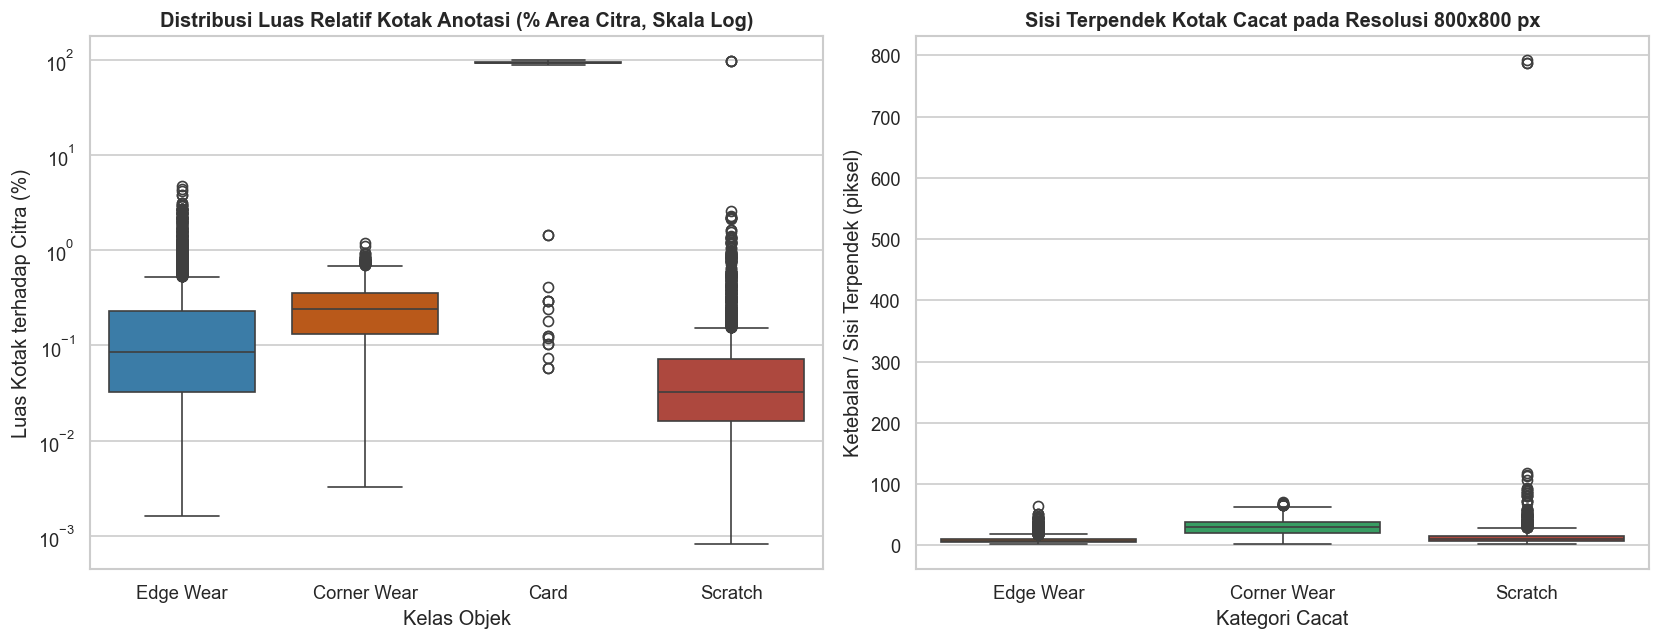

In [13]:
# PLOT 2: Scale Imbalance (Luas Relatif Objek % dan Dimensi Minimum pada 800 px)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.boxplot(
    data=df_boxes, x="class_name", y="area_pct",
    hue="class_name", palette=PALETTE_HEX, legend=False, ax=axes[0]
)
axes[0].set_yscale("log")
axes[0].set_title("Distribusi Luas Relatif Kotak Anotasi (% Area Citra, Skala Log)", fontweight="bold")
axes[0].set_xlabel("Kelas Objek")
axes[0].set_ylabel("Luas Kotak terhadap Citra (%)")

df_boxes["min_dim_800px"] = df_boxes[["w_800px", "h_800px"]].min(axis=1)
sns.boxplot(
    data=df_boxes[df_boxes["class_name"] != "Card"], x="class_name", y="min_dim_800px",
    hue="class_name", palette=PALETTE_HEX[1:], legend=False, ax=axes[1]
)
axes[1].set_title("Sisi Terpendek Kotak Cacat pada Resolusi 800x800 px", fontweight="bold")
axes[1].set_xlabel("Kategori Cacat")
axes[1].set_ylabel("Ketebalan / Sisi Terpendek (piksel)")

plt.tight_layout()
p2 = OUTPUT_DIR / "eda_v5_bbox_scale_imbalance.png"
plt.savefig(p2, bbox_inches="tight")
plt.show()

## 3. Visualisasi Sampel Anotasi 4 Kelas (Gambar 3.1)
Mengambil sampel bersih yang memuat kombinasi cacat lengkap (`Corner Wear`, `Edge Wear`, `Scratch`, dan `Card`) untuk memastikan anotasi akurat dan dapat dilihat jelas pada laporan.

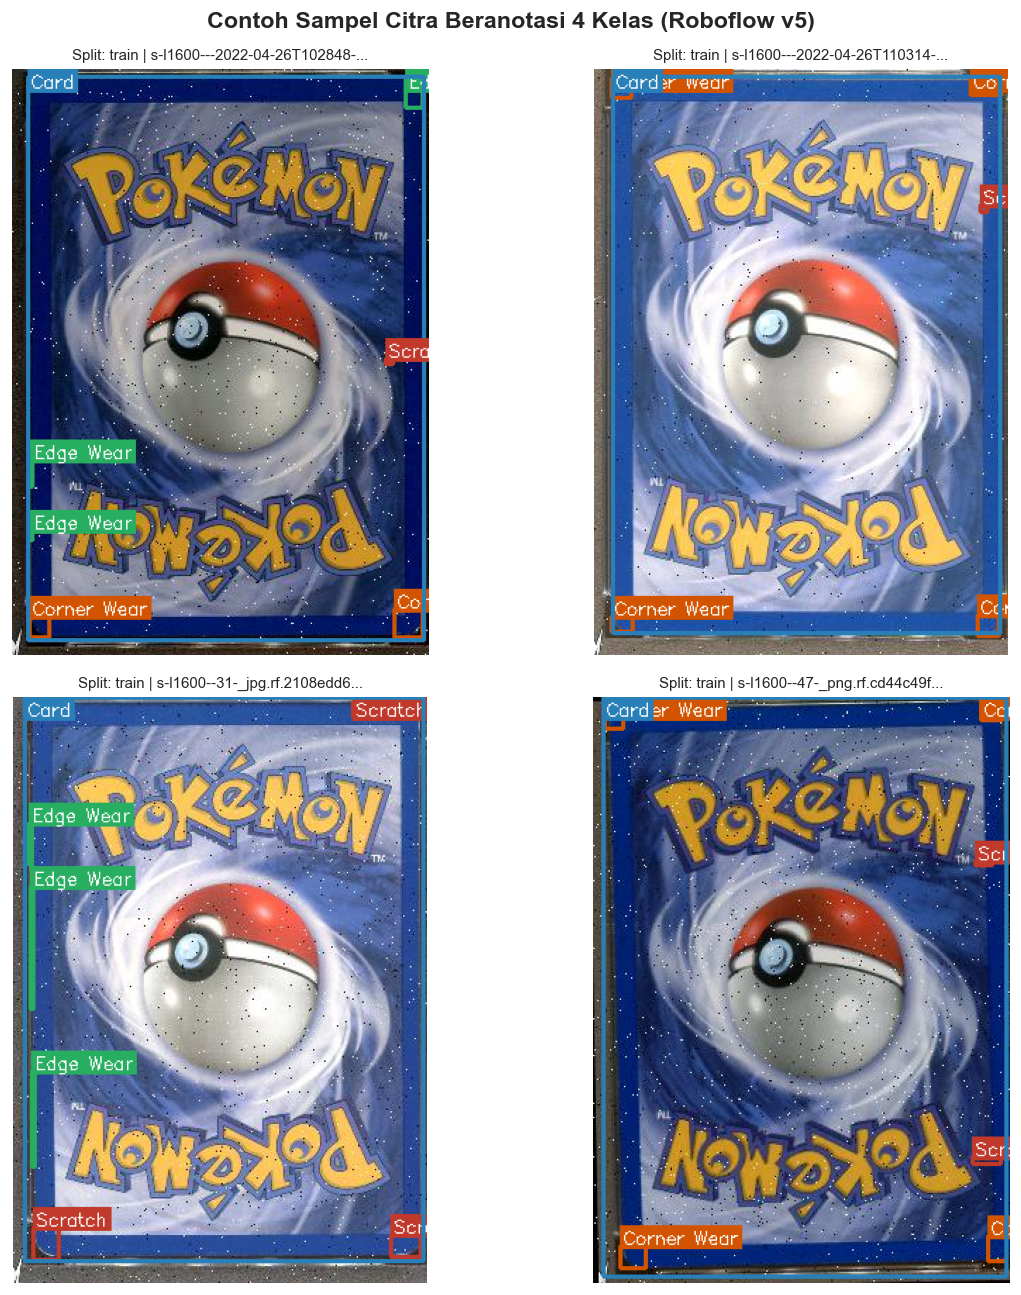

In [14]:
def draw_yolo_boxes(image_path, label_path):
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape
    if os.path.exists(label_path):
        with open(label_path, "r", encoding="utf-8") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                cls_id = int(parts[0])
                xc, yc, bw, bh = map(float, parts[1:])
                x1, y1 = max(0, int((xc - bw / 2) * w)), max(0, int((yc - bh / 2) * h))
                x2, y2 = min(w - 1, int((xc + bw / 2) * w)), min(h - 1, int((yc + bh / 2) * h))
                color = CLASS_COLORS_RGB[cls_id]
                label = CLASSES[cls_id]
                cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
                (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.42, 1)
                ly = max(y1, th + 4)
                cv2.rectangle(img, (x1, ly - th - 4), (x1 + tw + 4, ly + 2), color, -1)
                cv2.putText(img, label, (x1 + 2, ly - 1), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1)
    return img

# Pilih sampel dengan ragam kelas terbanyak agar informatif
richness = df_boxes.groupby("filename")["class_name"].nunique()
rich_files = richness[richness >= 3].index.tolist()
random.seed(42)
if len(rich_files) >= 4:
    chosen_names = random.sample(rich_files, 4)
else:
    chosen_names = random.sample(df_clean_imgs["filename"].tolist(), min(4, len(df_clean_imgs)))

sample_df = df_clean_imgs[df_clean_imgs["filename"].isin(chosen_names)].drop_duplicates("filename").head(4)

fig, axes = plt.subplots(2, 2, figsize=(11, 11))
fig.suptitle("Contoh Sampel Citra Beranotasi 4 Kelas (Roboflow v5)", fontsize=14, fontweight="bold")
for idx, (_, row) in enumerate(sample_df.iterrows()):
    ax = axes[idx // 2, idx % 2]
    ax.imshow(draw_yolo_boxes(row["img_path"], row["lbl_path"]))
    ax.set_title(f"Split: {row['split']} | {row['filename'][:28]}...", fontsize=9)
    ax.axis("off")

plt.tight_layout()
p3 = OUTPUT_DIR / "eda_v5_sample_annotations.png"
plt.savefig(p3, bbox_inches="tight")
plt.show()

## 4. Ringkasan Data Splitting & Visualisasi Pipeline Pra-Pemrosesan (Gambar 3.3)

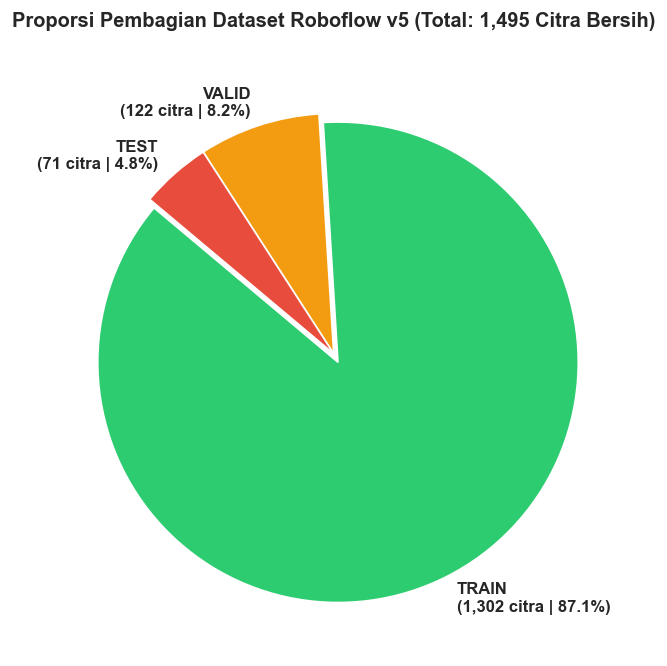

In [15]:
# PLOT 4: Visualisasi Rasio Pembagian Data Bersih
plt.figure(figsize=(6.5, 6.5))
labels_pie = [
    f"{row['Split'].upper()}\n({row['Citra Bersih Valid']:,} citra | {row['Proporsi (%)']:.1f}%)"
    for _, row in df_split_summary.iterrows()
]
plt.pie(
    df_split_summary["Citra Bersih Valid"],
    labels=labels_pie,
    colors=["#2ECC71", "#F39C12", "#E74C3C"],
    startangle=140,
    explode=(0.04, 0, 0),
    textprops={"fontsize": 10, "fontweight": "bold"},
)
plt.title(f"Proporsi Pembagian Dataset Roboflow v5 (Total: {df_split_summary['Citra Bersih Valid'].sum():,} Citra Bersih)", fontweight="bold", pad=16)
p4 = OUTPUT_DIR / "eda_v5_split_ratio.png"
plt.savefig(p4, bbox_inches="tight")
plt.show()

[*] Kartu dideteksi menggunakan fallback YOLOv8 ('Card' class).
[*] Skor ketajaman: 203.9 (ambang: 70)


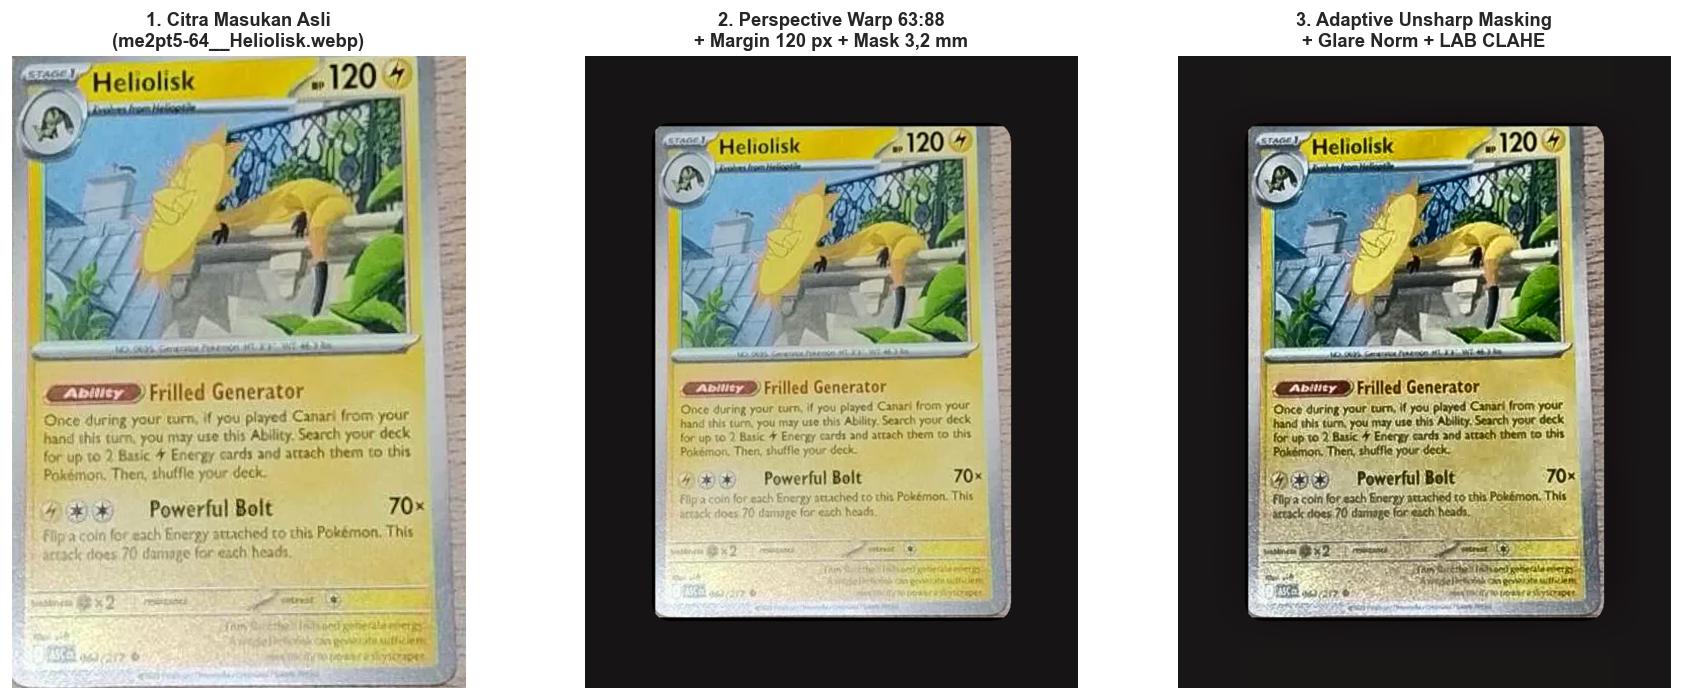

In [16]:
# PLOT 5: Ilustrasi Tahapan Pra-Pemrosesan Inferensi (Khusus Eksekusi Lokal dengan Modul Produksi)
if not IS_KAGGLE:
    if str(backend_dir) not in sys.path:
        sys.path.insert(0, str(backend_dir))
    from models.card_condition import auto_detect_card, enhance_card_for_defect

    # Cari 1 sampel foto kartu riil (prioritas val_samples, fallback ke test split)
    val_candidates = sorted(glob.glob(str(backend_dir / "dataset" / "val_samples" / "*.*")))
    test_candidates = df_clean_imgs[df_clean_imgs["split"] == "test"]["img_path"].tolist()
    sample_pool = val_candidates if val_candidates else test_candidates

    chosen_img = None
    warped_img = None
    for cand_path in sample_pool:
        bgr = cv2.imread(cand_path)
        if bgr is None:
            continue
        w_res = auto_detect_card(bgr)
        if w_res is not None:
            chosen_img = bgr
            warped_img = w_res
            chosen_name = Path(cand_path).name
            break

    if chosen_img is not None:
        enhanced_img = enhance_card_for_defect(warped_img, verbose=True)
        fig, axes = plt.subplots(1, 3, figsize=(15, 6))
        titles = [
            f"1. Citra Masukan Asli\n({chosen_name})",
            "2. Perspective Warp 63:88\n+ Margin 120 px + Mask 3,2 mm",
            "3. Adaptive Unsharp Masking\n+ Glare Norm + LAB CLAHE"
        ]
        for ax, im_bgr, ttl in zip(axes, [chosen_img, warped_img, enhanced_img], titles):
            ax.imshow(cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB))
            ax.set_title(ttl, fontsize=11, fontweight="bold")
            ax.axis("off")
        plt.tight_layout()
        p5 = OUTPUT_DIR / "eda_v5_preprocessing_steps.png"
        plt.savefig(p5, bbox_inches="tight")
        plt.show()
    else:
        print("Tidak ada sampel yang berhasil dideteksi konturnya untuk ilustrasi preprocessing.")
else:
    print("Berjalan di Kaggle: lewati sel modul lokal backend/models/card_condition.py.")